In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid")

# 1. 加载并清洗训练集
df = pd.read_csv('train.csv')
df['Age'] = df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Has_Cabin'] = df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

# 2. 训练模型
X = df.drop('Survived', axis=1)
y = df['Survived']
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)  # 注意：这次我们用全部数据训练

print("模型准备完毕！")

模型准备完毕！


# 泰坦尼克号生存预测分析报告

## 第 1 页：背景与目标
- **背景**：泰坦尼克号沉船事件是历史上最著名的海难之一。
- **目标**：利用乘客的性别、年龄、舱位等特征，构建机器学习模型，预测乘客的生存概率。
- **工具**：Python (Pandas, Scikit-learn, Seaborn)。

## 第 2 页：数据探索 (EDA)
- 数据集共 891 名乘客，12 个特征。
- 发现缺失值：'Age' 缺失约 20%，'Cabin' 缺失率高达 77%。

## 第 3 页：数据清洗与特征工程
- **年龄填充**：按性别分组，用各组的均值填充缺失年龄。
- **客舱处理**：将客舱号转化为二分类特征 `Has_Cabin`（有/无）。
- **文字编码**：将性别 (male/female) 和登船口 (S/C/Q) 转化为数字 (0/1/2)。

## 第 4 页：关键数据洞察 (可视化)
- **性别规律**：女性生存率高达 74%，男性仅 18%。印证了“女士优先”。
- **舱位规律**：头等舱生存率超过 63%，三等舱仅为 24%。

## 第 5 页：模型训练与结论
- **算法**：随机森林分类器 (Random Forest)。
- **性能**：在测试集上达到 **82.12%** 的准确率。
- **关键特征**：特征重要性排序依次为：性别 (Sex)、票价 (Fare)、年龄 (Age)。

In [2]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Has_Cabin
0,0,3,0,22.0,1,0,7.2500,0,0
1,1,1,1,38.0,1,0,71.2833,1,1
2,1,3,1,26.0,0,0,7.9250,0,0
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,0


/home/kylephelps/projects/kaggle-titanic/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kylephelps/projects/kaggle-titanic/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kylephelps/projects/kaggle-titanic/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kylephelps/projects/kaggle-titanic/venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 23384 (\N{CJK UNIFIED IDEOGRAPH-5B58}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/kylephelps/projects/kaggle-tit

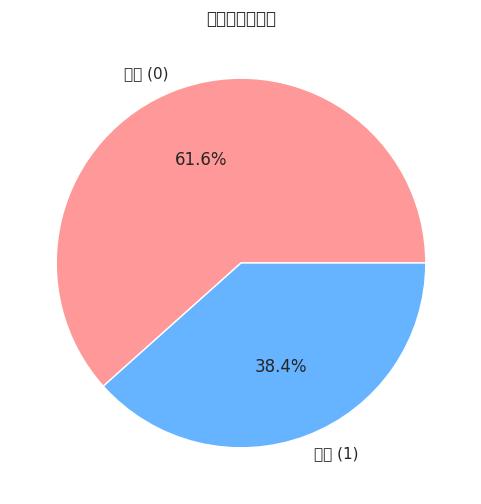

In [3]:
plt.figure(figsize=(6, 6))
df['Survived'].value_counts().plot.pie(autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], labels=['遇难 (0)', '幸存 (1)'])
plt.title('总体生存率分布')
plt.ylabel('')
plt.show()

/tmp/ipykernel_2407/3314842015.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, palette='Set2')


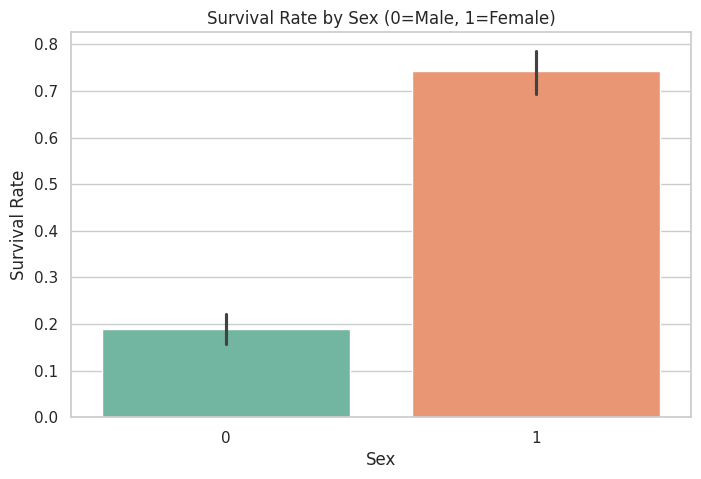

In [4]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Sex', y='Survived', data=df, palette='Set2')
plt.title('Survival Rate by Sex (0=Male, 1=Female)')
plt.ylabel('Survival Rate')
plt.show()

/tmp/ipykernel_2407/2231542033.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')


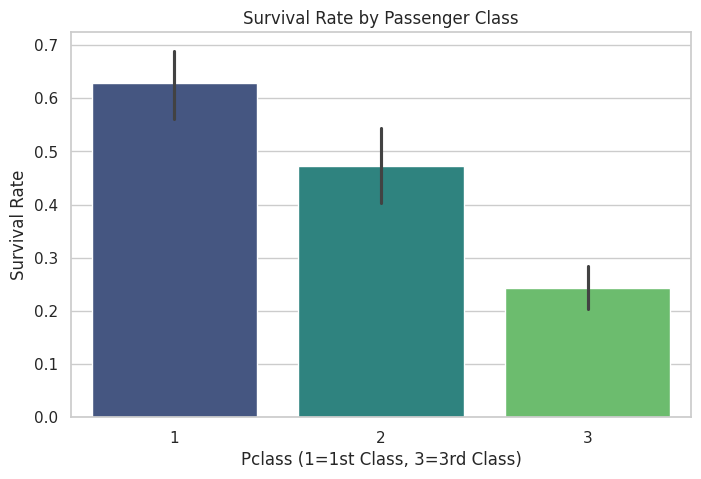

In [5]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=df, palette='viridis')
plt.title('Survival Rate by Passenger Class')
plt.ylabel('Survival Rate')
plt.xlabel('Pclass (1=1st Class, 3=3rd Class)')
plt.show()

In [ ]:
df.info()

In [2]:
# 导入机器学习工具
from sklearn.model_selection import train_test_split

# X 是特征（除 Survived 之外的所有列），y 是标签（Survived 列）
X = df.drop('Survived', axis=1)
y = df['Survived']

print(f"特征维度: {X.shape}")
print(f"标签维度: {y.shape}")

特征维度: (891, 8)
标签维度: (891,)


In [ ]:
df.describe()

In [3]:
# 划分数据集：80%训练，20%测试
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"训练集样本数: {len(X_train)}")
print(f"测试集样本数: {len(X_test)}")

训练集样本数: 712
测试集样本数: 179


In [4]:
from sklearn.ensemble import RandomForestClassifier

# 初始化模型
model = RandomForestClassifier(n_estimators=100, random_state=42)

# 开始训练模型（这是最核心的一步，AI 正在疯狂学习规律）
model.fit(X_train, y_train)
print("AI 模型训练完成！")

AI 模型训练完成！


In [5]:
from sklearn.metrics import accuracy_score

# 让 AI 预测测试集
predictions = model.predict(X_test)

# 计算准确率
accuracy = accuracy_score(y_test, predictions)
print(f"AI 在测试集上的预测准确率: {accuracy * 100:.2f}%")

AI 在测试集上的预测准确率: 82.12%


/tmp/ipykernel_1372/2009036425.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette='viridis')


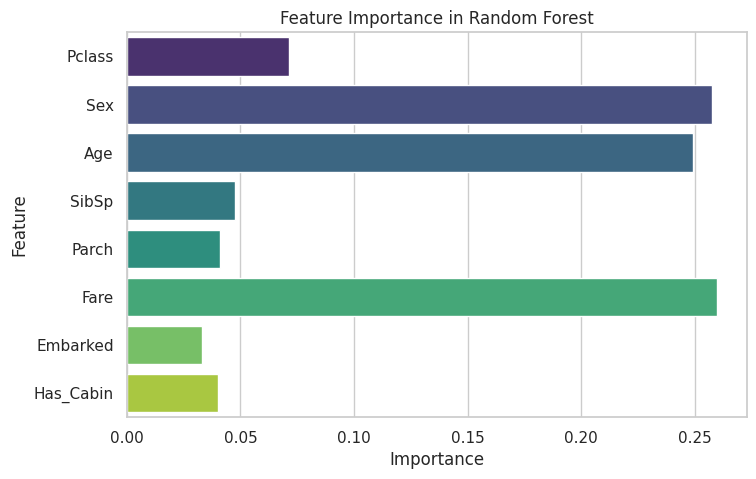

In [6]:
# 获取特征重要性
importances = model.feature_importances_
features = X.columns

# 画图
plt.figure(figsize=(8, 5))
sns.barplot(x=importances, y=features, palette='viridis')
plt.title('Feature Importance in Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [ ]:
# 统计幸存者人数
survived_counts = df['Survived'].value_counts()
print(survived_counts)
print(f"幸存率: {survived_counts[1] / len(df) * 100:.2f}%")

In [ ]:
df['Age'] = df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 重新读取数据
df = pd.read_csv('train.csv')

In [ ]:
# 按照性别分组，用各自性别的平均年龄填充缺失值
df['Age'] = df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))

In [ ]:
f['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [ ]:
df['Age'] = df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))

In [ ]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [ ]:
df['Has_Cabin'] = df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)

In [ ]:
# 性别
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
# 登船口
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

In [ ]:
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

In [ ]:
df.info()

In [8]:
# 直接读取本地的 train.csv 模拟新数据，并去掉答案列
test_df = pd.read_csv('train.csv')
test_df = test_df.drop('Survived', axis=1)
print("准备完毕，共", len(test_df), "条数据")

准备完毕，共 891 条数据


In [9]:
# 清洗
test_df['Age'] = test_df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))
test_df['Embarked'] = test_df['Embarked'].fillna(test_df['Embarked'].mode()[0])
test_df['Has_Cabin'] = test_df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)
test_df['Sex'] = test_df['Sex'].map({'male': 0, 'female': 1})
test_df['Embarked'] = test_df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# 提取 PassengerId
passenger_ids = test_df['PassengerId']

# 删掉无用列
test_df = test_df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
print("清洗完毕！")

清洗完毕！


In [6]:
# 假装这是 Kaggle 发给我们的新数据（我们故意去掉 Survived 答案）
test_df = pd.read_csv('train.csv')
test_df = test_df.drop('Survived', axis=1)

# 对测试集进行与训练集完全相同的清洗
test_df['Age'] = test_df.groupby('Sex')['Age'].transform(lambda x: x.fillna(x.mean()))
test_df['Embarked'] = test_df['Embarked'].fillna(test_df['Embarked'].mode()[0])
test_df['Has_Cabin'] = test_df['Cabin'].apply(lambda x: 0 if pd.isna(x) else 1)
test_df['Sex'] = test_df['Sex'].map({'male': 0, 'female': 1})
test_df['Embarked'] = test_df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# 保存 PassengerId 用于生成最终提交文件
passenger_ids = test_df['PassengerId']

# 去掉无用列，保持与训练集特征完全一致
test_df = test_df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

print("测试集处理完毕，准备预测！")

测试集处理完毕，准备预测！


In [10]:
# 预测
predictions = model.predict(test_df)

# 组装提交格式
submission = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': predictions
})

# 导出 CSV
submission.to_csv('submission.csv', index=False)

print("✅ 成功！已生成 submission.csv")

✅ 成功！已生成 submission.csv


In [7]:
# AI 开始预测（0 或 1）
predictions = model.predict(test_df)

# 组装 Kaggle 要求的格式：PassengerId, Survived
submission = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': predictions
})

# 导出为 CSV 文件
submission.to_csv('submission.csv', index=False)

print("✅ 预测成功！已生成 submission.csv")
print(f"预测的幸存总人数: {submission['Survived'].sum()} / {len(submission)}")

✅ 预测成功！已生成 submission.csv
预测的幸存总人数: 334 / 891
